# 06 – Hồi quy Tuyến tính OLS, Chẩn đoán 4 Giả định LINE & Mở rộng Đa Trạm 2022–2026 (Issue #12, W10)

**Môn học:** INFO3020 – Nhập môn Khoa học Dữ liệu (*Introduction to Data Science*) – ĐH CMC<br>
**Dữ liệu nguồn:**
- Baseline: `data/processed/air_pollution_final.parquet` (`VN001_HANOI_556_NGUYEN_VAN_CU`, 07/2025–07/2026, mốc cắt `2026-01-15`)
- Mở rộng (Issue #44/#50): `data/processed/air_pollution_extended_2022_2026.parquet` (`VN001_HANOI_556_NGUYEN_VAN_CU` và `VN003_HANOI_OPENAQ_7441` 01/2022–04/2025, mốc 80/20 tách trạm theo **Protocol A**)

---

## Trọng Tâm Thực Nghiệm (Issue #12 + W10 Slide + Scope Extension)

1. **Chống rò rỉ dữ liệu & Protocol A/B:** Từ chối fail-closed việc gộp đa trạm lệch thời gian (Protocol B); toàn bộ imputer/scaler đặt trong `Pipeline` fit từng fold CV và kiểm chứng bằng `validate_no_leakage()`.
2. **Kiểm toán VIF & 4 Giả định LINE:**
   - **L (Linearity):** Kiểm định Ramsey **RESET** (bậc 2 & 3) + đường cong **LOWESS**, không dựa vào tính chất đại số $\text{corr}(\hat{e}, \hat{y}) \equiv 0$.
   - **I (Independence):** Durbin-Watson, ACF phần dư và độ nhạy sai số chuẩn **HAC Newey-West** qua các độ trễ $L \in \{0, L_{\text{NW plug-in}}, 12, 24, 48, 72, 168\}$.
   - **N (Normality):** Normal Q-Q, Jarque-Bera, Shapiro-Wilk (khi $n \le 5000$) và kiểm chứng $\log(1 + \text{PM}_{2.5})$ trên Train.
   - **E (Equal Variance):** Breusch-Pagan & Scale-Location kèm LOWESS.
3. **Điểm đòn bẩy & Ảnh hưởng:** Phân tách Outliers ($|\text{stud\_resid}| > 3$), High Leverage ($h_{ii} > 2p/n$), Cook's $D$ ($>4/n$, $>0,5$, $>1,0$).
4. **Giải phẫu $R^2$ âm, Ablation & Độ ổn định:** Thử nghiệm bỏ chu kỳ mùa `month_sin/cos`, bổ sung `pm25_lag24` nội trạm, Rolling-Origin CV trong Train, độ ổn định phân tầng kèm $n_{\text{eff}}$, và độ nhạy `pm25_derived_interpolated` (chỉ trên Train).


In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, display

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from src.regression import (
    DEFAULT_SPLIT_TIMESTAMP,
    EXTENDED_HISTORICAL_STATION,
    PRIMARY_BASELINE_STATION,
    prepare_regression_data,
    run_extended_regression_suite,
)

BASELINE_PATH = REPO_ROOT / "data" / "processed" / "air_pollution_final.parquet"
EXTENDED_PATH = REPO_ROOT / "data" / "processed" / "air_pollution_extended_2022_2026.parquet"
FIG_DIR = REPO_ROOT / "figures"
REPORT_PATH = REPO_ROOT / "reports" / "regression_results.md"

print(f"Baseline Parquet: {BASELINE_PATH.exists()} ({BASELINE_PATH})")
print(f"Extended Parquet: {EXTENDED_PATH.exists()} ({EXTENDED_PATH})")


Baseline Parquet: True (C:\Users\ASUS\Documents\GitHub\air-pollution-analysis\data\processed\air_pollution_final.parquet)
Extended Parquet: True (C:\Users\ASUS\Documents\GitHub\air-pollution-analysis\data\processed\air_pollution_extended_2022_2026.parquet)


## 1. Kiểm Chứng Chặn Gộp Đa Trạm (Protocol B Guard) & Thực Thi Bộ 3 Phạm Vi (Protocol A)


In [2]:
if EXTENDED_PATH.exists():
    df_ext = pd.read_parquet(EXTENDED_PATH)
    try:
        prepare_regression_data(df_ext, use_split_column=True, station_id=None)
    except ValueError as exc:
        print("✓ Fail-closed Protocol B Guard hoạt động đúng:", exc)

suite = run_extended_regression_suite(
    baseline_path=BASELINE_PATH,
    extended_path=EXTENDED_PATH if EXTENDED_PATH.exists() else None,
    figures_dir=FIG_DIR,
    report_path=REPORT_PATH,
)

summary_rows = []
for name, res in suite.items():
    mt = res.metrics_table.set_index("Model")
    d = res.line_diagnostics
    summary_rows.append({
        "Run": name,
        "Station": res.station_id,
        "Train": res.n_train,
        "Test": res.n_test,
        "Dummy RMSE": mt.loc["Baseline (Dummy Mean)", "RMSE (µg/m³)"],
        "OLS MAE": mt.loc["OLS Linear Regression", "MAE (µg/m³)"],
        "OLS RMSE": mt.loc["OLS Linear Regression", "RMSE (µg/m³)"],
        "OLS Test R²": mt.loc["OLS Linear Regression", "R²"],
        "RESET(2) F": round(d.reset_power2_f, 2),
        "RESET(2) p": f"{d.reset_power2_pvalue:.2e}",
        "DW": round(d.durbin_watson, 4),
        "ACF(1)": round(float(d.acf_values[1]), 4),
    })

display(pd.DataFrame(summary_rows))


✓ Fail-closed Protocol B Guard hoạt động đúng: Phát hiện nhiều trạm ['VN001_HANOI_556_NGUYEN_VAN_CU', 'VN003_HANOI_OPENAQ_7441'] khi chưa chỉ định `station_id`. Cấm gộp đa trạm theo Protocol B vì các trạm lệch pha thời gian (ví dụ VN003 2022–2025 vs VN001 2025–2026). Hãy truyền `station_id` cụ thể để phân tích theo Protocol A.


,Run,Station,Train,Test,Dummy RMSE,OLS MAE,OLS RMSE,OLS Test R²,RESET(2) F,RESET(2) p,DW,ACF(1)
0,VN001_baseline,VN001_HANOI_556_NGUYEN_VAN_CU,4279,3216,24.46,37.32,41.46,-1.9540,223.27,3.02e-49,0.2430,0.8785
1,VN001_extended,VN001_HANOI_556_NGUYEN_VAN_CU,6749,746,24.15,15.63,21.12,-0.1073,615.42,4.40e-130,0.2079,0.8960
2,VN003_extended,VN003_HANOI_OPENAQ_7441,13835,4373,37.73,23.98,32.82,0.1498,243.15,2.35e-54,0.3033,0.8484


## 2. Trạm Chính VN001 Baseline (`2026-01-15`) — VIF, Hệ Số HAC & Độ Nhạy Độ Trễ L


In [3]:
res_b = suite["VN001_baseline"]
print("Bảng VIF trên Train (chú ý biến có 5 <= VIF < 10):")
display(res_b.vif_table)

print("\nBảng hệ số OLS (Classical vs HAC-24):")
display(res_b.coefficients.drop(columns=["p_hac_num"], errors="ignore"))

print(f"\nĐộ nhạy p-value theo độ trễ HAC (NW plug-in = {res_b.line_diagnostics.plugin_nw_maxlags}h):")
display(res_b.hac_sensitivity_table.pivot(index="lag_label", columns="Feature", values="p_display"))


Bảng VIF trên Train (chú ý biến có 5 <= VIF < 10):


,Feature,VIF
0,surface_pressure,8.061
1,temperature,7.655
2,month_cos,4.470
3,relative_humidity,2.456
4,month_sin,2.301
5,hour_cos,2.063
6,hour_sin,1.404
7,wind_speed,1.138
8,precipitation,1.130



Bảng hệ số OLS (Classical vs HAC-24):


,Feature,Coefficient (Beta),SE (Classical),p-Value (Classical),SE (HAC-24),p-Value (HAC-24),95% CI Lower (HAC),95% CI Upper (HAC)
const,const,309.9997,139.7387,0.0266,589.6235,0.5991,-845.6410,1465.6404
temperature,temperature,0.1664,0.1984,0.4017,0.7805,0.8312,-1.3634,1.6961
relative_humidity,relative_humidity,0.0638,0.0407,0.1173,0.1219,0.6005,-0.1751,0.3027
wind_speed,wind_speed,-6.0673,0.3029,2.27e-85,1.1173,5.63e-08,-8.2572,-3.8774
precipitation,precipitation,-0.9471,0.3448,0.0060,0.5424,0.0808,-2.0102,0.1160
surface_pressure,surface_pressure,-0.2450,0.1345,0.0685,0.5659,0.6651,-1.3542,0.8643
hour_sin,hour_sin,3.5160,0.6141,1.10e-08,1.2907,0.0064,0.9862,6.0458
hour_cos,hour_cos,3.4884,0.7454,2.96e-06,1.4025,0.0129,0.7396,6.2373
month_sin,month_sin,28.8563,1.2786,1.22e-106,5.0855,1.39e-08,18.8890,38.8236
month_cos,month_cos,12.3294,1.1395,6.15e-27,3.9078,0.0016,4.6702,19.9886



Độ nhạy p-value theo độ trễ HAC (NW plug-in = 9h):


Feature,precipitation,relative_humidity,surface_pressure,temperature,wind_speed
lag_label,,,,,
0 (HC1),0.0004,0.1568,0.1389,0.5092,7.14e-66
12,0.0583,0.5422,0.5938,0.7984,1.14e-10
168,0.0790,0.6658,0.7416,0.8523,7.38e-05
24,0.0808,0.6005,0.6651,0.8312,5.63e-08
48,0.0814,0.6490,0.7122,0.8537,1.76e-06
72,0.0807,0.6593,0.7254,0.8578,4.59e-06
9 (NW plug-in),0.0477,0.5172,0.5599,0.7829,2.98e-12


## 3. Chẩn Đoán LINE, Phân Loại Ảnh Hưởng, Ablation $R^2 < 0$ & Rolling-Origin CV (VN001 Baseline)


In [4]:
d = res_b.line_diagnostics
print(f"Ramsey RESET(p=2): F = {d.reset_power2_f:.2f}, p = {d.reset_power2_pvalue:.2e} -> Linearity VIOLATED = {d.linearity_violated}")
print(f"Ramsey RESET(p=3): F = {d.reset_power3_f:.2f}, p = {d.reset_power3_pvalue:.2e}")
print(f"Durbin-Watson = {d.durbin_watson:.4f}, ACF(1) = {d.acf_values[1]:.4f}, ACF(24) = {d.acf_values[24]:.4f}")
print(f"Jarque-Bera = {d.jarque_bera_stat:.1f} (p = {d.jarque_bera_pvalue:.2e}), Skew = {d.skewness:.3f}, Excess Kurtosis = {d.kurtosis:.3f}")
print(f"Breusch-Pagan LM = {d.breusch_pagan_stat:.2f} (p = {d.breusch_pagan_pvalue:.2e})")
print(f"Log1p Skew Comparison: original={res_b.log1p_metrics['original_resid_skew']:.3f} vs log1p={res_b.log1p_metrics['log1p_resid_skew']:.3f}")

inf = res_b.influence_summary
print("\nPhân loại Outliers / High Leverage / Influential Points:")
print({k: v for k, v in inf.items() if k != "top_influential"})
display(inf["top_influential"])

print("\nThử nghiệm Ablation giải phẫu R² âm & Rolling-Origin CV:")
display(res_b.ablation_table)
print("Chẩn đoán dịch chuyển phân phối:", res_b.ablation_diagnostics)
display(res_b.rolling_origin_cv)


Ramsey RESET(p=2): F = 223.27, p = 3.02e-49 -> Linearity VIOLATED = True
Ramsey RESET(p=3): F = 116.26, p = 6.86e-50
Durbin-Watson = 0.2430, ACF(1) = 0.8785, ACF(24) = 0.4019
Jarque-Bera = 392.7 (p = 5.32e-86), Skew = 0.554, Excess Kurtosis = 0.988
Breusch-Pagan LM = 658.27 (p = 6.44e-136)
Log1p Skew Comparison: original=0.554 vs log1p=-0.958

Phân loại Outliers / High Leverage / Influential Points:
{'n_obs': 4279, 'p_params': 10, 'cooks_threshold_4n': 0.0009347978499649451, 'n_cooks_gt_4n': 267, 'pct_cooks_gt_4n': 6.239775648516009, 'n_cooks_gt_05': 0, 'n_cooks_gt_10': 0, 'cooks_max': 0.017413147526769184, 'leverage_threshold_2pn': 0.004673989249824725, 'n_high_leverage': 137, 'leverage_max': 0.08406979753295528, 'stud_resid_threshold': 3.0, 'n_outliers_stud_gt_3': 42, 'n_outlier_and_high_leverage': 8}


,timestamp,pm25_obs,fitted,residual,stud_resid,leverage,cooks_d
0,2025-07-22 05:00:00+07:00,72.66,0.93,71.72,3.021,0.01875,0.01741
1,2025-07-22 08:00:00+07:00,96.25,2.93,93.32,3.918,0.01091,0.01688
2,2025-07-22 09:00:00+07:00,86.81,-2.28,89.09,3.741,0.01154,0.01629
3,2025-07-22 07:00:00+07:00,91.69,1.37,90.32,3.792,0.01113,0.01614
4,2025-07-22 06:00:00+07:00,89.00,2.38,86.62,3.636,0.01116,0.01488
5,2025-07-22 01:00:00+07:00,66.67,3.49,63.18,2.654,0.01345,0.00959
6,2025-11-29 03:00:00+07:00,153.56,69.95,83.61,3.501,0.00622,0.00765
7,2025-07-22 02:00:00+07:00,68.66,6.52,62.14,2.606,0.01045,0.00717
8,2025-11-29 02:00:00+07:00,156.54,67.65,88.90,3.721,0.00515,0.00714
9,2025-11-29 04:00:00+07:00,138.74,67.17,71.56,2.997,0.00698,0.00630



Thử nghiệm Ablation giải phẫu R² âm & Rolling-Origin CV:


,Specification,n_train,n_test,Train R²,Test MAE (µg/m³),Test RMSE (µg/m³),Test R²,Mean Bias (Pred−Obs)
0,Baseline (Dummy Mean),4279,3216,0.0000,18.91,24.46,-0.0280,4.04
1,OLS Full (9 biến: khí tượng + giờ + mùa),4279,3216,0.3747,37.32,41.46,-1.9540,33.78
2,OLS Bỏ chu kỳ mùa (7 biến: bỏ month_sin/cos),4279,3216,0.2790,19.51,25.99,-0.1604,1.35
3,OLS Chỉ khí tượng (5 biến),4279,3216,0.2782,19.52,25.95,-0.1568,1.31
4,"OLS Khí tượng + Giờ + pm25_lag24 (8 biến, AR)",4013,3010,0.5277,15.31,21.12,0.2245,-1.25


Chẩn đoán dịch chuyển phân phối: {'train_pm25_mean': 45.49794954460641, 'test_pm25_mean': 41.458310470106184, 'ols_full_test_pred_mean': 75.23591138157113, 'ols_full_mean_bias': 33.77760091146496, 'ols_full_test_r2': -1.9540005614296638, 'test_month_sin_out_of_train_range_pct': 64.98756218905473, 'train_month_sin_range': (-1.0, 0.49999999999999994), 'test_month_sin_range': (-0.4999999999999997, 1.0), 'ols_drop_season_test_r2': -0.16035268741990016, 'ols_drop_season_mean_bias': 1.3498937652650087, 'ols_lag24_test_r2': 0.22453462662186374, 'ols_lag24_test_rmse': 21.115037458648953, 'ols_lag24_test_mae': 15.306424085005197}


,Fold,n_train_fold,n_val_fold,Val Window,Dummy RMSE,OLS MAE,OLS RMSE,OLS R²
0,1,714,713,2025-08-03 → 2025-09-05,16.63,14.58,18.41,-0.6382
1,2,1427,713,2025-09-05 → 2025-10-07,17.29,13.82,18.84,-0.1890
2,3,2140,713,2025-10-07 → 2025-11-08,20.79,18.03,23.45,-0.2780
3,4,2853,713,2025-11-08 → 2025-12-11,47.84,38.35,48.13,-0.7649
4,5,3566,713,2025-12-12 → 2026-01-14,47.41,27.82,34.26,0.0738


## 4. Kết Quả Mở Rộng Lịch Sử Đa Năm (VN001 Extended 80/20 & VN003 2022–2025)


In [5]:
for key in ["VN001_extended", "VN003_extended"]:
    if key in suite:
        r = suite[key]
        print(f"=== {key} ({r.station_id}) | Train={r.n_train:,}, Test={r.n_test:,} ===")
        display(r.metrics_table)
        display(r.ablation_table)
        if not r.stratified_stability.empty:
            print("Độ ổn định hệ số phân tầng (kèm rho1 & n_eff):")
            display(r.stratified_stability)
        if r.derived_sensitivity is not None:
            ds = r.derived_sensitivity
            print(
                f"Độ nhạy pm25_derived_interpolated (Train-only): +{ds['n_derived_hours_added_in_train']}h, "
                f"max|ΔBeta|={ds['max_abs_beta_diff']:.4f}, "
                f"Test RMSE obs={ds['test_rmse_observed_model']:.2f} vs der_train={ds['test_rmse_derived_train_model']:.2f}"
            )


=== VN001_extended (VN001_HANOI_556_NGUYEN_VAN_CU) | Train=6,749, Test=746 ===


,Model,MAE (µg/m³),RMSE (µg/m³),R²,Adjusted R²
0,Baseline (Dummy Mean),20.40,24.15,-0.4487,-0.4487
1,OLS Linear Regression,15.63,21.12,-0.1073,-0.1209
2,Ridge (alpha=1000.000),16.60,21.11,-0.1069,-0.1205
3,Lasso (alpha=1.151),15.87,20.61,-0.0549,-0.0678


,Specification,n_train,n_test,Train R²,Test MAE (µg/m³),Test RMSE (µg/m³),Test R²,Mean Bias (Pred−Obs)
0,Baseline (Dummy Mean),6749,746,0.0000,20.40,24.15,-0.4487,13.44
1,OLS Full (9 biến: khí tượng + giờ + mùa),6749,746,0.2541,15.63,21.12,-0.1073,-3.15
2,OLS Bỏ chu kỳ mùa (7 biến: bỏ month_sin/cos),6749,746,0.1855,17.67,22.17,-0.2201,5.37
3,OLS Chỉ khí tượng (5 biến),6749,746,0.1847,17.78,22.28,-0.2324,5.63
4,"OLS Khí tượng + Giờ + pm25_lag24 (8 biến, AR)",6402,621,0.4512,13.44,17.50,0.0587,0.51


Độ ổn định hệ số phân tầng (kèm rho1 & n_eff):


,Stratum,n_obs,rho1_resid,n_eff,Train R²,wind_speed Beta,wind_speed p(HAC),precip Beta,precip p(HAC)
0,Year 2025,3966,0.899,212,0.2364,-6.180,4.72e-08,-1.919,5.30e-06
1,Year 2026,2783,0.904,141,0.1915,-9.132,2.23e-17,-0.938,0.1277
2,Season Summer (Jun-Aug),1326,0.855,104,0.1385,-0.036,0.9728,-1.026,0.0523
3,Season Autumn (Sep-Nov),2017,0.861,150,0.2105,-7.863,1.83e-10,-1.467,0.0023
4,Season Winter (Dec-Feb),1958,0.902,100,0.2571,-12.464,1.07e-20,-2.132,0.2167
5,Season Spring (Mar-May),1448,0.862,108,0.2633,-5.409,4.59e-09,-0.621,0.2598


Độ nhạy pm25_derived_interpolated (Train-only): +117h, max|ΔBeta|=17.7253, Test RMSE obs=21.12 vs der_train=21.14
=== VN003_extended (VN003_HANOI_OPENAQ_7441) | Train=13,835, Test=4,373 ===


,Model,MAE (µg/m³),RMSE (µg/m³),R²,Adjusted R²
0,Baseline (Dummy Mean),26.42,37.73,-0.1235,-0.1235
1,OLS Linear Regression,23.98,32.82,0.1498,0.1481
2,Ridge (alpha=59.636),24.00,32.91,0.1456,0.1438
3,Lasso (alpha=0.281),23.98,33.06,0.1377,0.1359


,Specification,n_train,n_test,Train R²,Test MAE (µg/m³),Test RMSE (µg/m³),Test R²,Mean Bias (Pred−Obs)
0,Baseline (Dummy Mean),13835,4373,0.0000,26.42,37.73,-0.1235,-12.51
1,OLS Full (9 biến: khí tượng + giờ + mùa),13835,4373,0.2329,23.98,32.82,0.1498,-3.79
2,OLS Bỏ chu kỳ mùa (7 biến: bỏ month_sin/cos),13835,4373,0.1723,24.86,34.27,0.0735,-5.81
3,OLS Chỉ khí tượng (5 biến),13835,4373,0.1703,24.88,34.26,0.0738,-5.86
4,"OLS Khí tượng + Giờ + pm25_lag24 (8 biến, AR)",12871,4206,0.3476,20.27,28.70,0.3490,-2.69


Độ ổn định hệ số phân tầng (kèm rho1 & n_eff):


,Stratum,n_obs,rho1_resid,n_eff,Train R²,wind_speed Beta,wind_speed p(HAC),precip Beta,precip p(HAC)
0,Year 2022,3079,0.874,207,0.1718,-9.507,1.05e-16,-1.696,0.0075
1,Year 2023,5646,0.836,504,0.2685,-5.447,1.49e-13,-1.722,8.17e-05
2,Year 2024,5110,0.863,376,0.0640,-2.958,7.40e-06,-1.753,6.53e-06
3,Season Winter (Dec-Feb),3979,0.878,259,0.1687,-10.689,2.51e-25,-12.092,0.0103
4,Season Spring (Mar-May),3462,0.855,270,0.0886,-2.574,0.0002,-1.351,0.0026
5,Season Summer (Jun-Aug),3799,0.779,472,0.0315,-2.589,3.02e-06,-0.543,0.0309
6,Season Autumn (Sep-Nov),2595,0.789,305,0.1798,-8.601,2.02e-21,-1.241,0.1365


Độ nhạy pm25_derived_interpolated (Train-only): +150h, max|ΔBeta|=2.6827, Test RMSE obs=32.82 vs der_train=32.83


## 5. Biểu Đồ Chẩn Đoán LINE (300 DPI kèm LOWESS) & Báo Cáo Nghiệm Thu


Hiển thị regression_line_diagnostics.png:


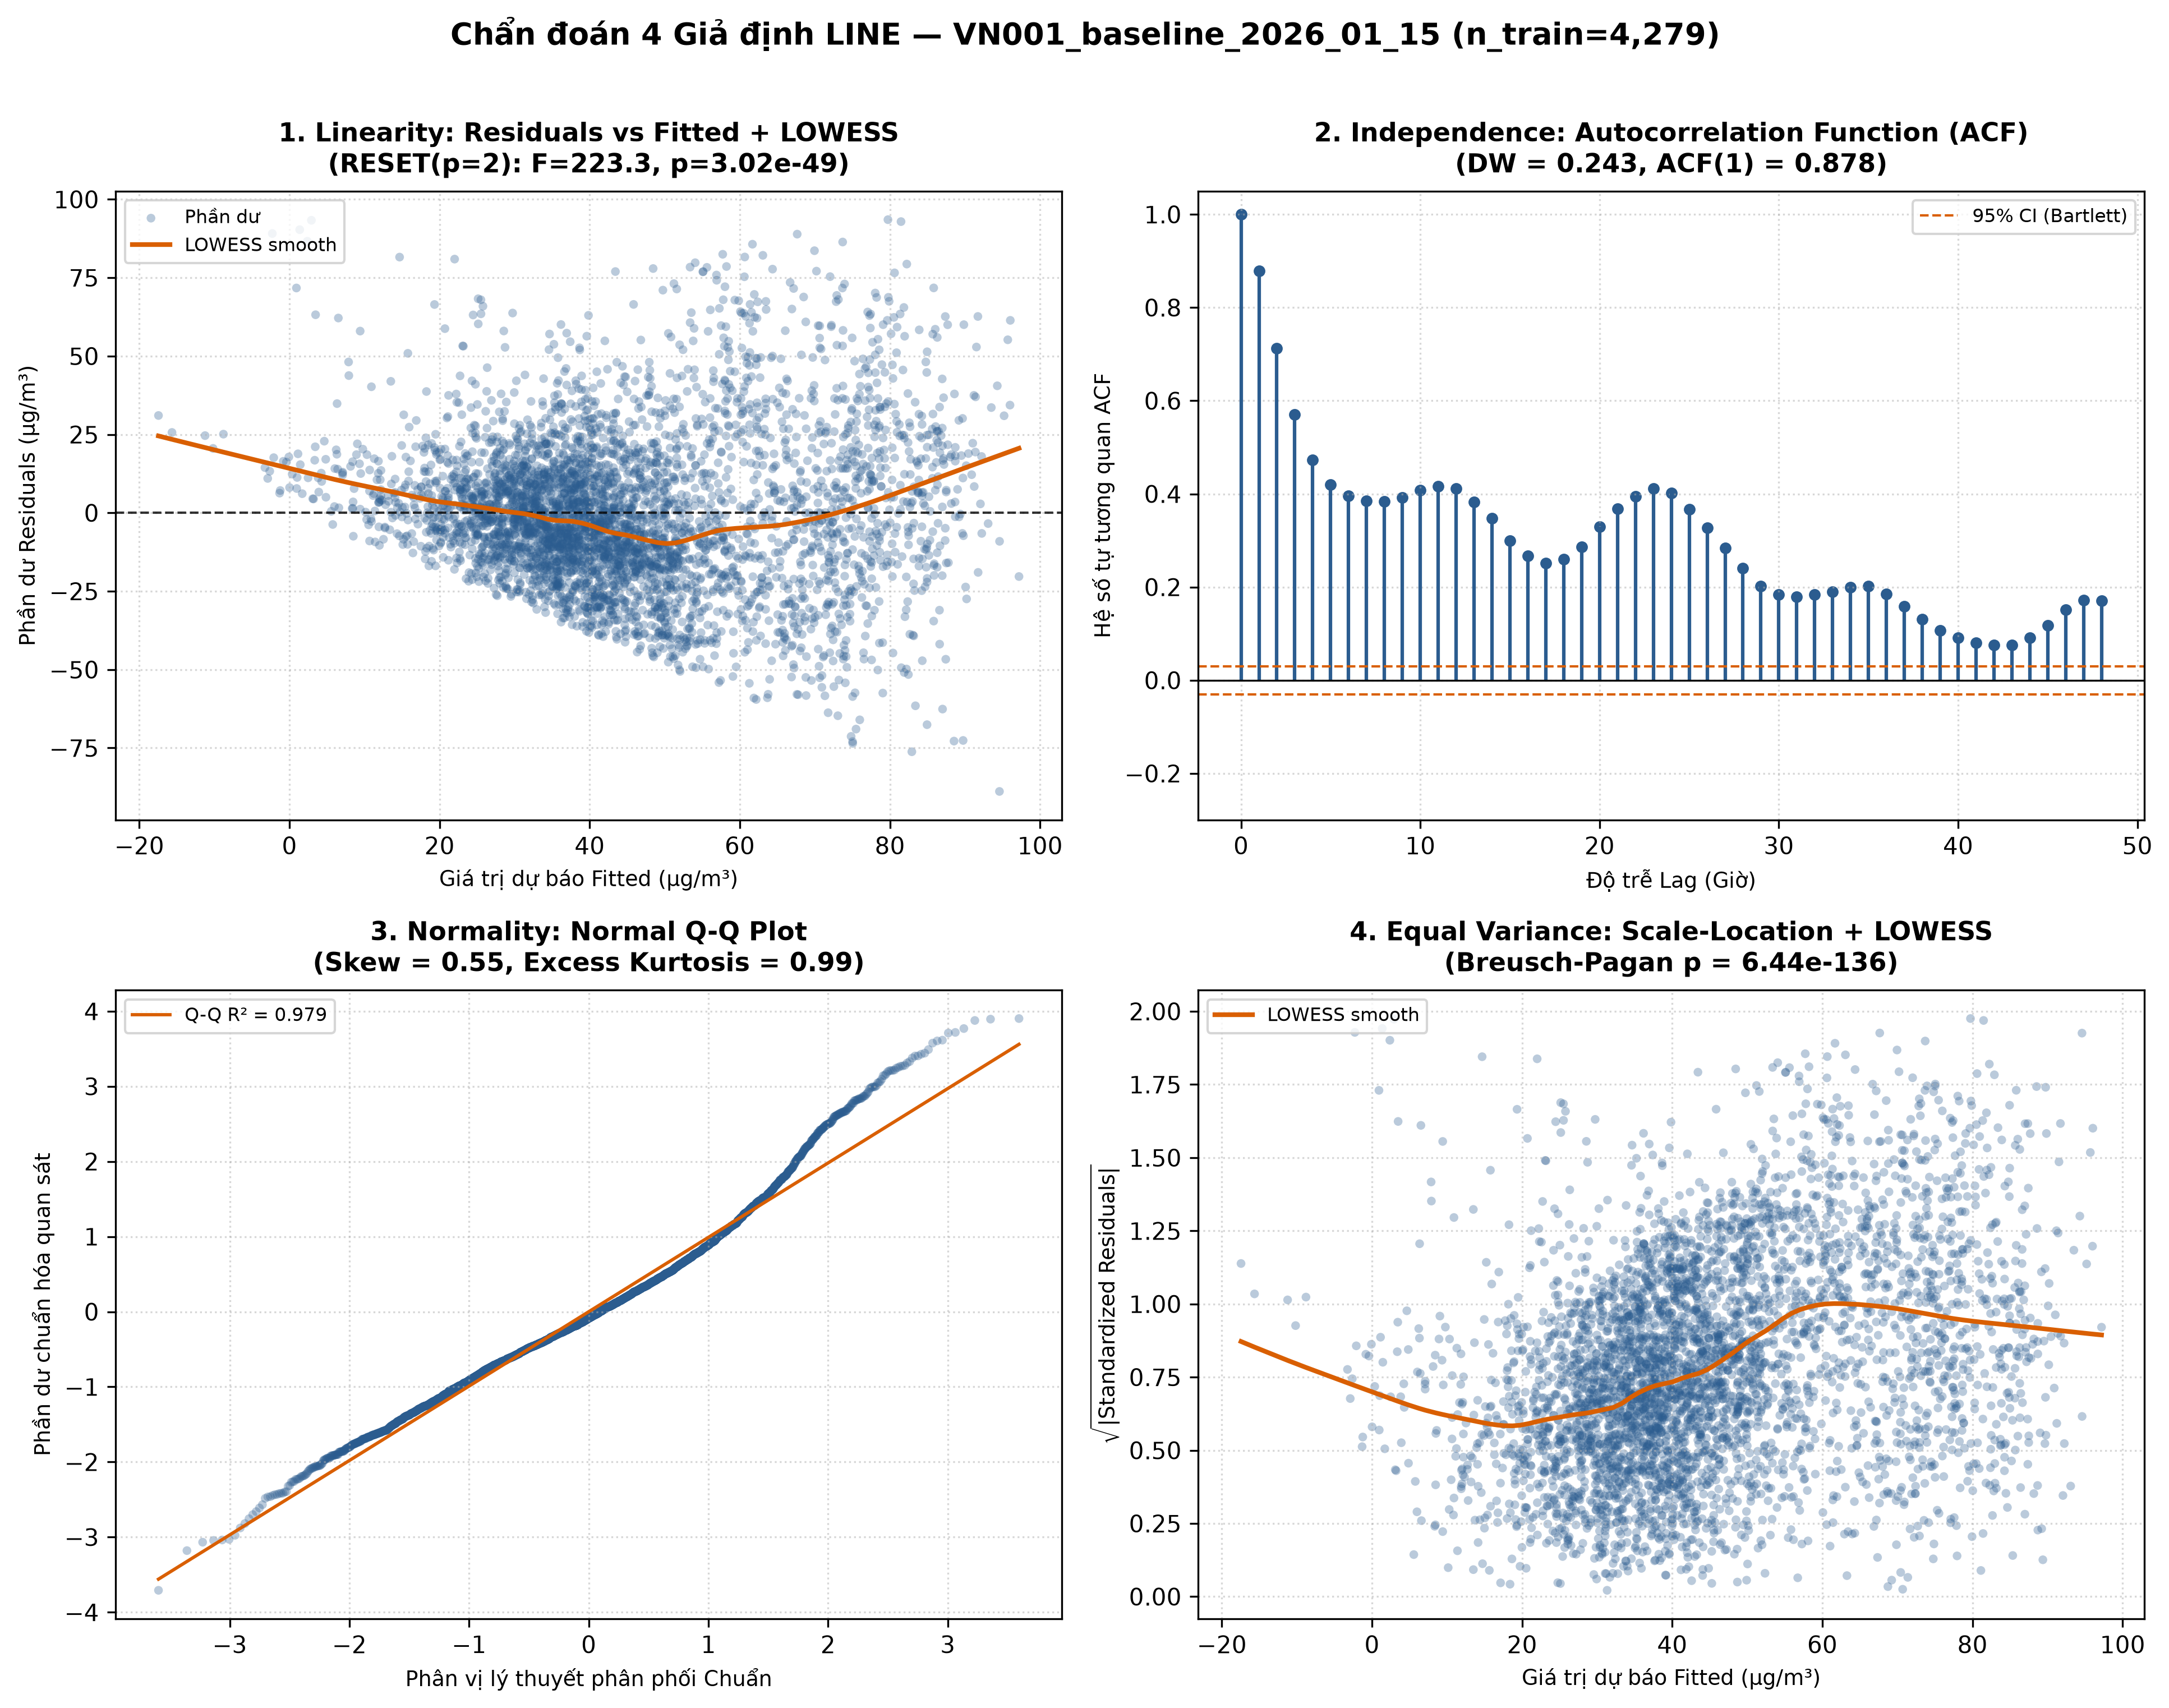

Hiển thị regression_line_diagnostics_vn003_extended.png:


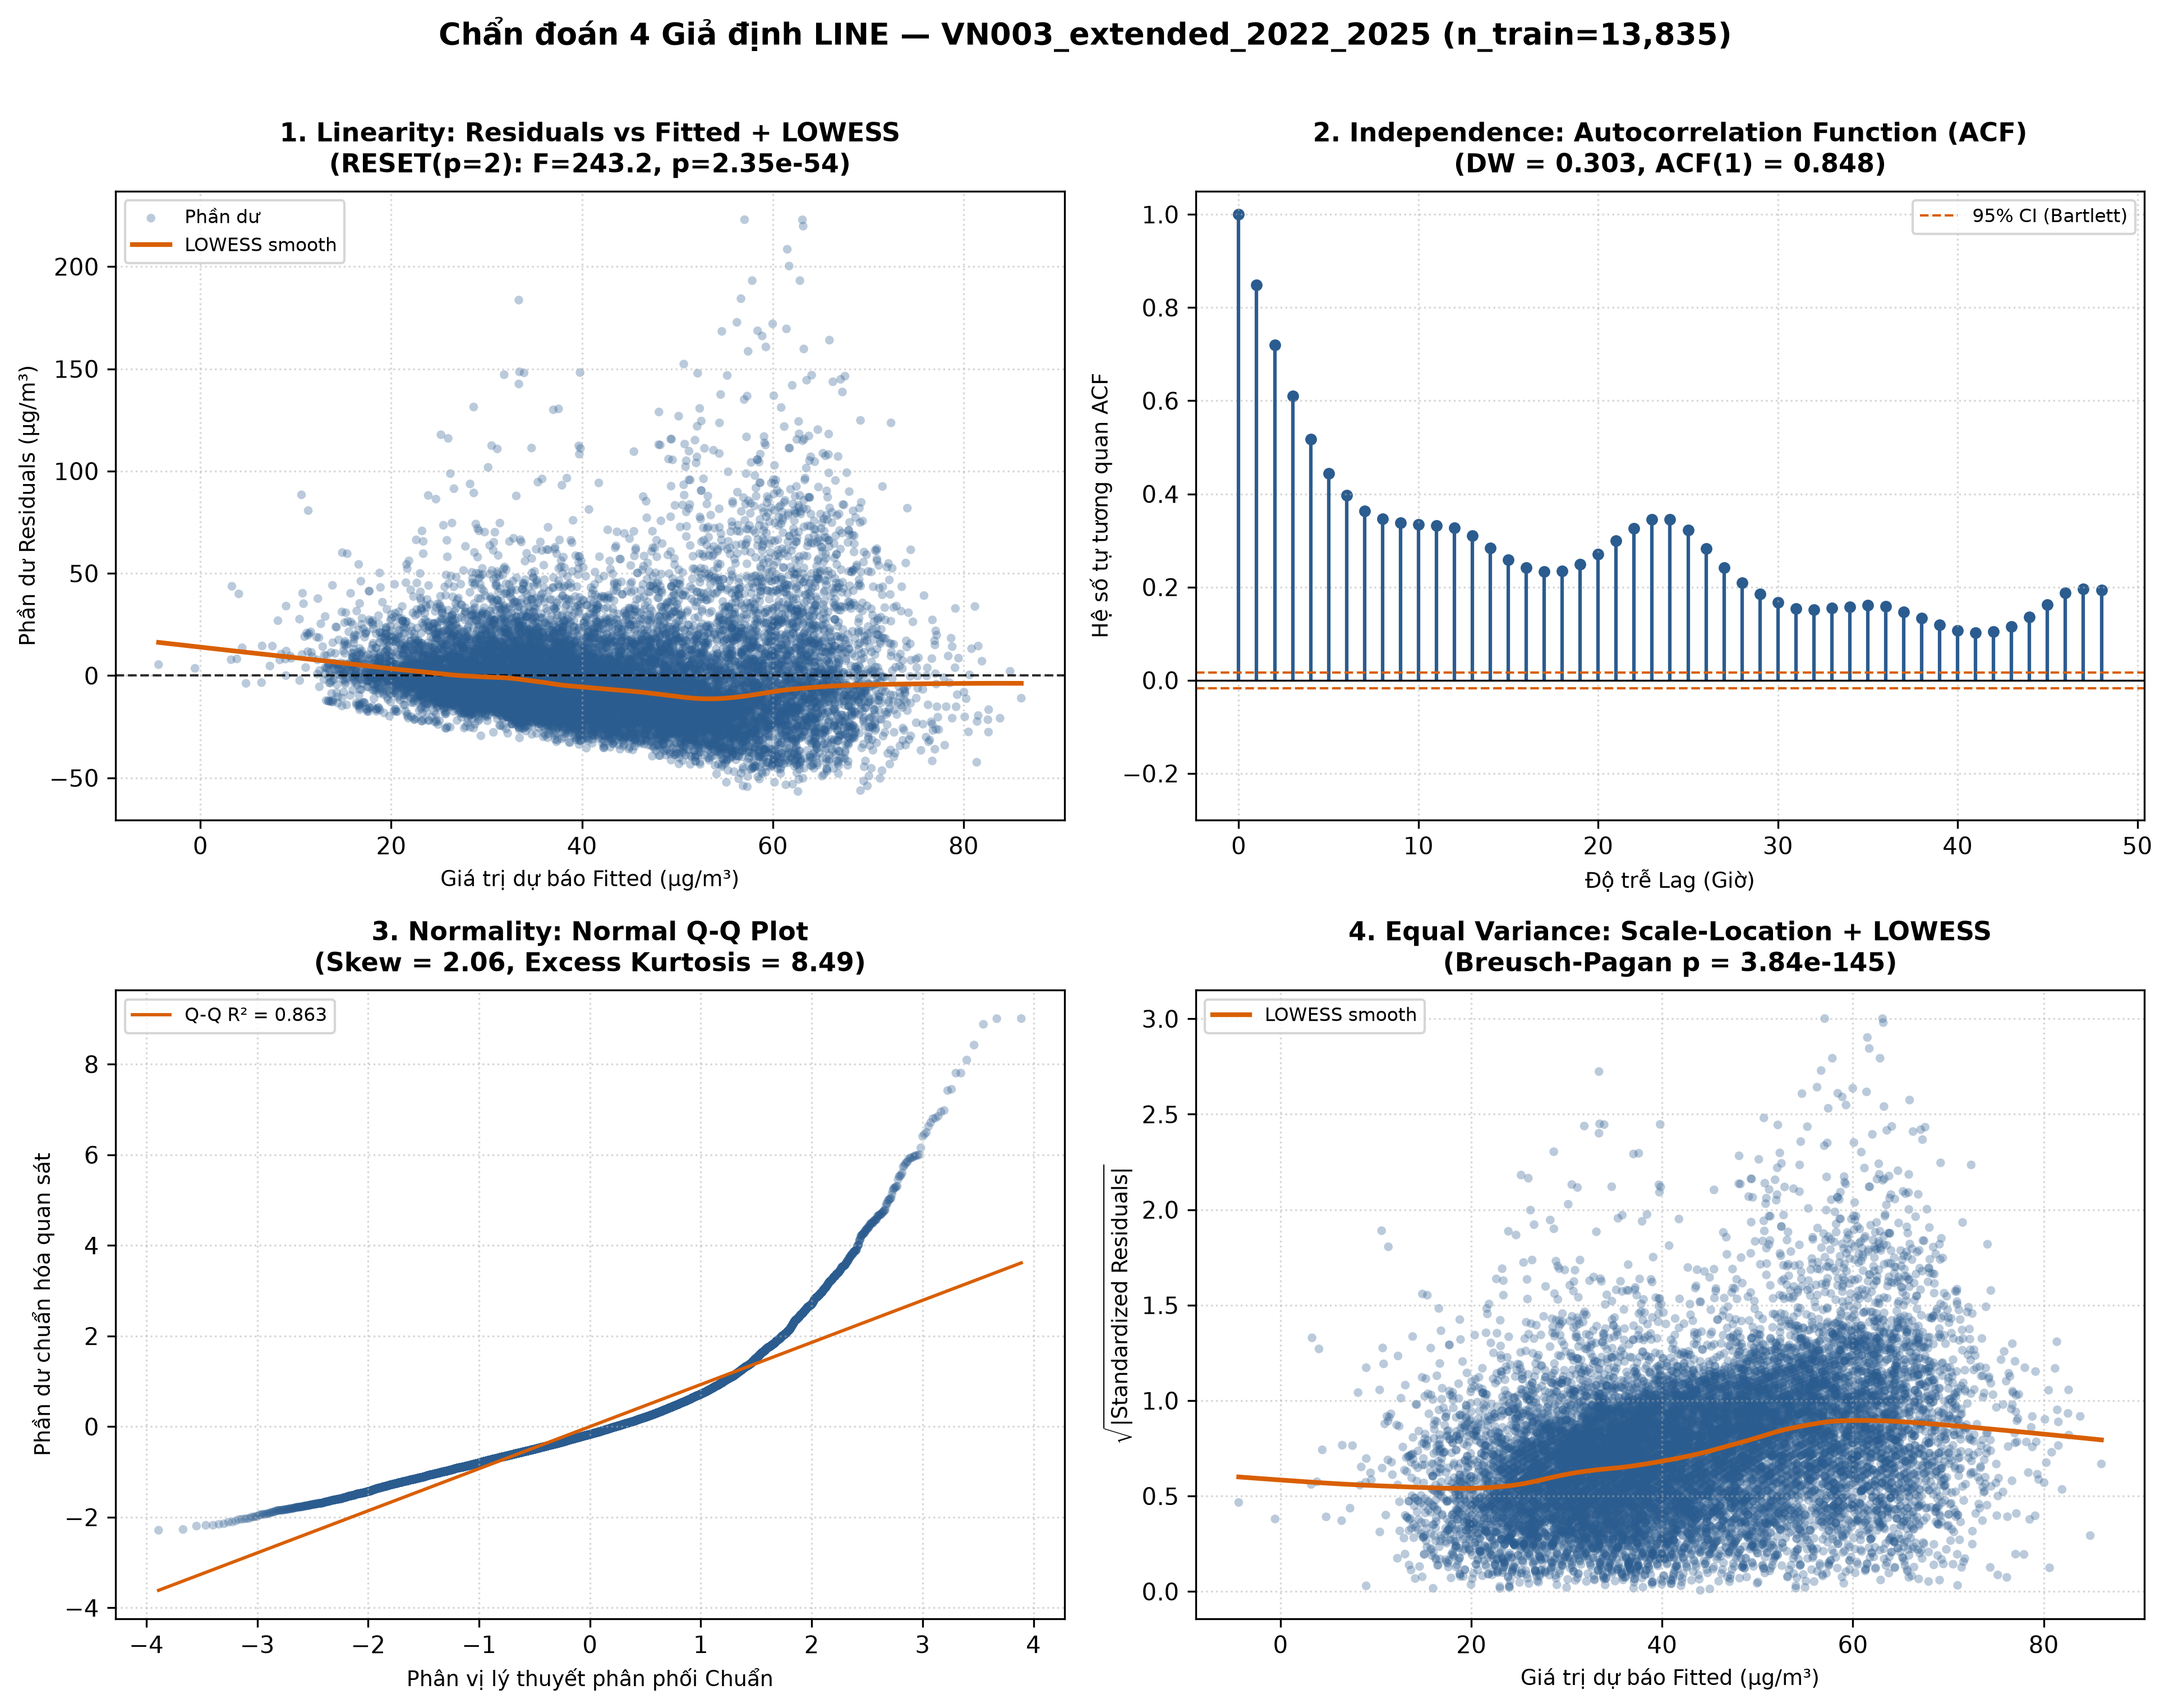

Đã xuất báo cáo động: C:\Users\ASUS\Documents\GitHub\air-pollution-analysis\reports\regression_results.md (48,339 bytes)


In [6]:
fig_base = FIG_DIR / "regression_line_diagnostics.png"
if fig_base.exists():
    print(f"Hiển thị {fig_base.name}:")
    display(Image(filename=str(fig_base)))

fig_vn003 = FIG_DIR / "regression_line_diagnostics_vn003_extended.png"
if fig_vn003.exists():
    print(f"Hiển thị {fig_vn003.name}:")
    display(Image(filename=str(fig_vn003)))

print(f"Đã xuất báo cáo động: {REPORT_PATH.resolve()} ({REPORT_PATH.stat().st_size:,} bytes)")
